# Archivio: prime analisi delle differenze di ToF

Origine: `~/juno/pos/prova/graph.ipynb`.

Copia organizzata per la consultazione: le celle eseguibili e gli output originali sono conservati. I titoli aggiunti sono celle Markdown; i risultati salvati non sono stati ricalcolati. Eseguire dalla cartella di questo notebook. I dati ROOT esterni e gli eventuali problemi già presenti sono descritti in `docs/DATI_E_PERCORSI.md` nella radice del repository.


## Distribuzione globale e controlli sugli eventi


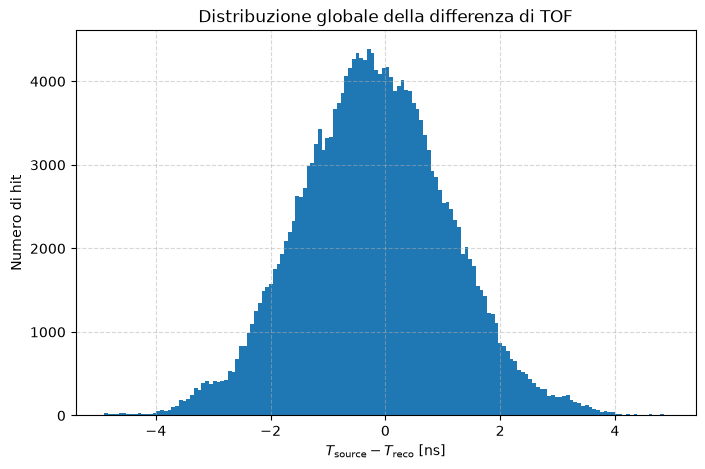

In [11]:
import uproot
import numpy as np
import matplotlib.pyplot as plt

with uproot.open("output.root") as file:
    tree = file["tof_cal"]
    data = tree.arrays(library="np")

delta = data["delta_ns"]

# delta = delta[np.isfinite(delta)]

plt.figure(figsize=(8, 5))
plt.hist(delta, bins=150)
plt.xlabel(r"$T_{\mathrm{source}}-T_{\mathrm{reco}}$ [ns]")
plt.ylabel("Numero di hit")
plt.title("Distribuzione globale della differenza di TOF")
plt.grid(alpha=0.5, linestyle= '--')
plt.show()

In [12]:
print(data["event_id"][-1])

2842


In [2]:
print("Media:", np.mean(delta), "ns")
print("Mediana:", np.median(delta), "ns")
print("Deviazione standard:", np.std(delta), "ns")

Media: -0.19075302371710315 ns
Mediana: -0.20503487930389497 ns
Deviazione standard: 1.297839780598067 ns


## Differenza relativa di ToF


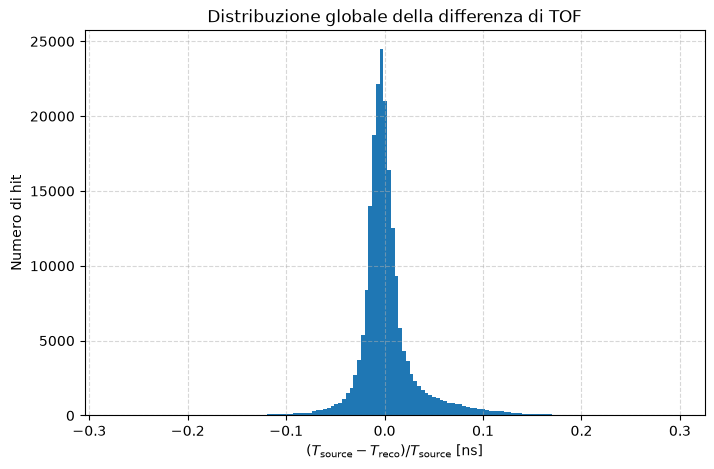

Media: 0.002457407108642847 ns
Mediana: -0.002170768771919475 ns
Deviazione standard: 0.03178236888760992 ns


In [3]:
tof_source = data["tof_source_ns"]
delta_rel= delta/tof_source

plt.figure(figsize=(8, 5))
plt.hist(delta_rel, bins=150)
plt.xlabel(r"$(T_{\mathrm{source}}-T_{\mathrm{reco}}) / T_{\mathrm{source}}$ [ns]")
plt.ylabel("Numero di hit")
plt.title("Distribuzione globale della differenza di TOF")
plt.grid(alpha=0.5, linestyle= '--')
plt.show()

print("Media:", np.mean(delta_rel), "ns")
print("Mediana:", np.median(delta_rel), "ns")
print("Deviazione standard:", np.std(delta_rel), "ns")

## Distribuzione per un singolo PMT


[    0     1     2     3     4     6    11    13    14    15    16    17
    21    23    24    25    26    27    28    29    30    31    32    33
    34    35    36    37    38    39    40    41    42    43    44    45
    46    47    48    49    50    51    52    53    54    55    56    57
    58    59    62    63    65    66    67    68    69    70    71    72
    73    74    75    76    77    78    79    80    81    82    83    84
    85    86    87    88    89    91    92    93    94    95    96    97
    98    99   100   101   102   103   104   105   106   107   108   110
   111   112   113   114   115   116   118   119   120   121   122   123
   124   125   127   128   130   132   133   134   135   136   137   138
   139   140   141   142   143   144   145   146   147   148   149   151
   152   153   154   155   157   158   159   160   161   162   163   164
   165   166   167   168   170   171   172   173   174   175   176   177
   179   181   182   183   184   185   186   187   

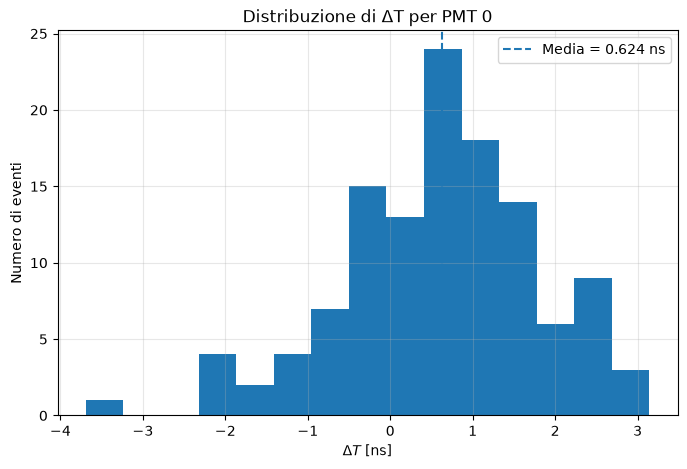

In [3]:
pmt_ids, counts = np.unique(data["pmt_id"], return_counts=True)

valid_pmts = pmt_ids[counts >= 100]

print(valid_pmts)

mask = data["pmt_id"] == 0
delta_pmt = data["delta_ns"][mask]

plt.figure(figsize=(8, 5))
plt.hist(delta_pmt, bins=15)
plt.axvline(np.mean(delta_pmt), linestyle="--",
            label=f"Media = {np.mean(delta_pmt):.3f} ns")
plt.xlabel(r"$\Delta T$ [ns]")
plt.ylabel("Numero di eventi")
plt.title(f"Distribuzione di ΔT per PMT 0")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Bias medio per PMT


4908


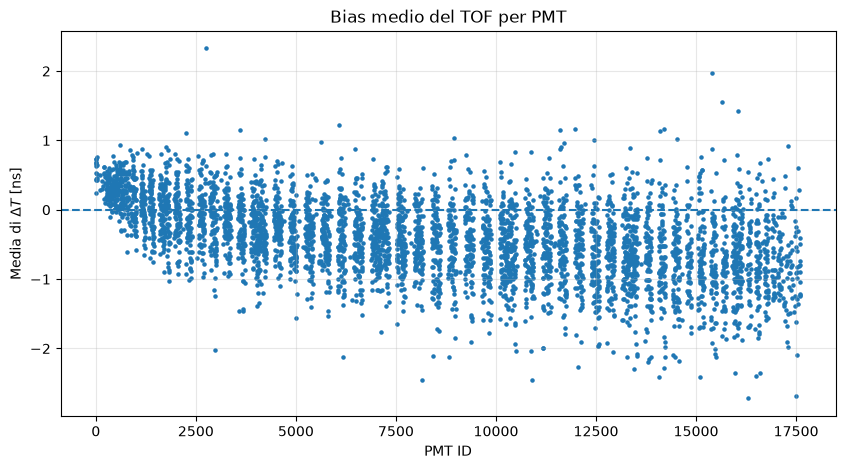

In [4]:
pmt_id = data["pmt_id"]
delta = data["delta_ns"]

pmt_id= pmt_id[data["pmt_type"]]
delta = delta[data["pmt_type"]]
unique_pmts = np.unique(pmt_id)
print(len(unique_pmts))

mean_delta = np.empty(len(unique_pmts))
std_delta = np.empty(len(unique_pmts))
n_entries = np.empty(len(unique_pmts), dtype=int)

for i, current_pmt in enumerate(unique_pmts):
    values = delta[pmt_id == current_pmt]
    values = values[np.isfinite(values)]

    n_entries[i] = len(values)
    mean_delta[i] = np.mean(values)
    std_delta[i] = np.std(values, ddof=1) if len(values) > 1 else np.nan

plt.figure(figsize=(10, 5))
plt.scatter(unique_pmts, mean_delta, s=5)
plt.axhline(0.0, linestyle="--")
plt.xlabel("PMT ID")
plt.ylabel(r"Media di $\Delta T$ [ns]")
plt.title("Bias medio del TOF per PMT")
plt.grid(alpha=0.3)
plt.show()

## Distribuzione spaziale del bias


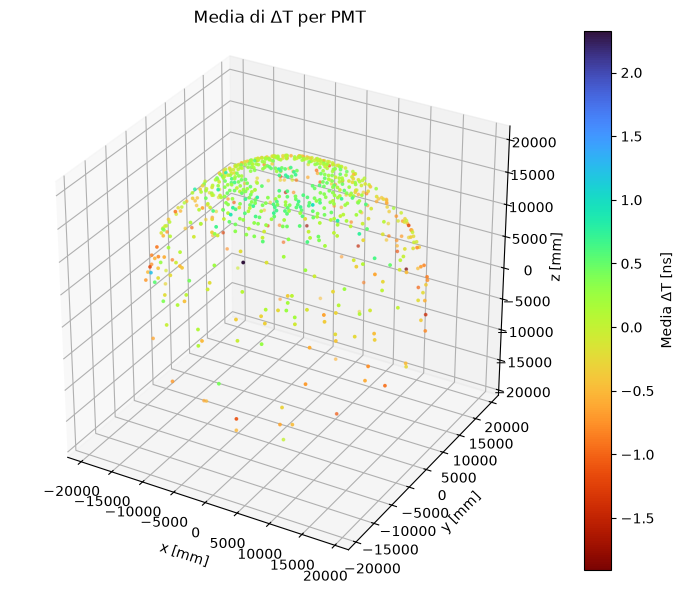

In [10]:
import pandas as pd

positions = pd.read_csv("pmt_positions.csv", sep=r"\s+", header=None, names=["pmt_id", "x", "y", "z", "type"])

statistics = pd.DataFrame({
    "pmt_id": unique_pmts,
    "mean_delta": mean_delta,
    "std_delta": std_delta,
    "n_entries": n_entries
})

mask = statistics["n_entries"]>15
pmt_map = positions.merge(statistics, on="pmt_id", how="inner")

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

points = ax.scatter(pmt_map["x"][mask],pmt_map["y"][mask],pmt_map["z"][mask],c=pmt_map["mean_delta"][mask],cmap='turbo_r', s=3)

ax.set_xlabel("x [mm]")
ax.set_ylabel("y [mm]")
ax.set_zlabel("z [mm]")
ax.set_title("Media di ΔT per PMT")

fig.colorbar(points, ax=ax, label="Media ΔT [ns]")
plt.gca().set_aspect('equal')
plt.show()

## Dipendenza dal ToF della sorgente


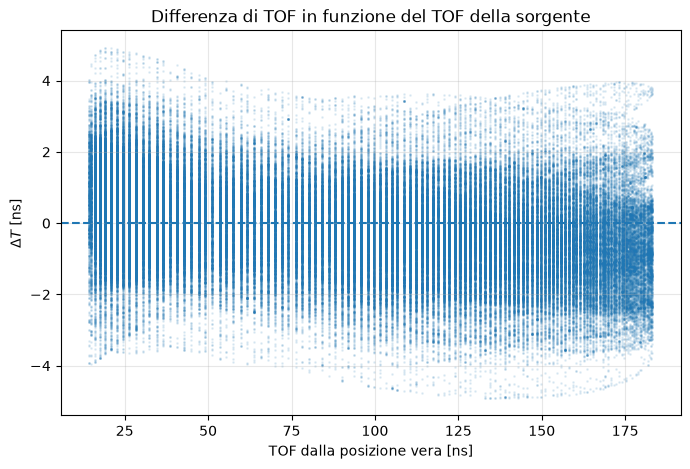

In [42]:
plt.figure(figsize=(8, 5))
plt.scatter(
    data["tof_source_ns"],
    data["delta_ns"],
    s=1,
    alpha=0.1
)

plt.axhline(0.0, linestyle="--")
plt.xlabel("TOF dalla posizione vera [ns]")
plt.ylabel(r"$\Delta T$ [ns]")
plt.title("Differenza di TOF in funzione del TOF della sorgente")
plt.grid(alpha=0.3)
plt.show()

## Densità degli hit nel piano ToF–differenza temporale


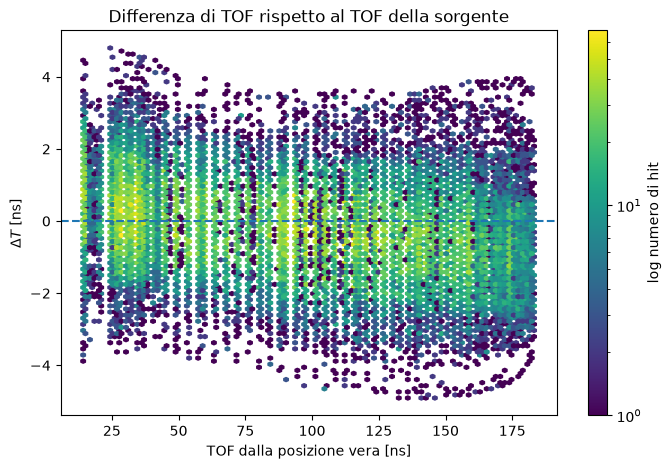

In [46]:
plt.figure(figsize=(8, 5))

tof_s = data["tof_source_ns"][data["pmt_type"]]
delta = data["delta_ns"][data["pmt_type"]]
plot = plt.hexbin(
    tof_s,
    delta,
    gridsize=100,
    mincnt=1,
    bins="log"
)

plt.axhline(0.0, linestyle="--")
plt.xlabel("TOF dalla posizione vera [ns]")
plt.ylabel(r"$\Delta T$ [ns]")
plt.title("Differenza di TOF rispetto al TOF della sorgente")
plt.colorbar(plot, label="log numero di hit")
plt.show()